In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate

In [2]:
n0    = 0.15
n_b = [0.165, 0.32, 0.5344, 0.7500, 1]
K_b = [17906.60, 63.177, 774.375, 548.309 ]
Gam_b = [4.921, 0, 4.00,2.80]
m0 = [939.56, 1201.75, 1031.815, 958.55]


#K_b = [2.1680,63.178,0.5075,3.2401]
#n_b = np.array(n_b/n0)

In [3]:
@jit(nopython=True)
def P_from_nb(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def mu_from_nb(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def e_from_n(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

@jit(nopython=True)
def cs(mu,K,Gam,n_list):
    t1 = 1/mu
    t2 = K*Gam*((n_list)**(Gam-1))
    t = t1*t2
    return t

In [4]:
n1_b = np.linspace(n_b[0], n_b[1], 20)
P1_b = P_from_nb(n1_b, K_b[0], Gam_b[0])
mu1_b = mu_from_nb(n1_b, K_b[0], Gam_b[0], m0[0])
e1_b = e_from_n(n1_b, K_b[0], Gam_b[0], m0[0])
#cs_1 = cs(mu1_b,K_b[0],Gam_b[0],n_b[0])

n2_b = np.linspace(n_b[1], n_b[2], 20)
P2_b = P_from_nb(n2_b, K_b[1], Gam_b[1])
mu2_b = mu_from_nb(n2_b, K_b[1], Gam_b[1], m0[1])
e2_b = e_from_n(n2_b, K_b[1], Gam_b[1], m0[1])
#cs_2 = cs(mu2_b,K_b[1],Gam_b[1],n_b[1])

n3_b = np.linspace(n_b[2], n_b[3], 20)
P3_b = P_from_nb(n3_b, K_b[2], Gam_b[2])
mu3_b = mu_from_nb(n3_b, K_b[2], Gam_b[2], m0[2])
e3_b = e_from_n(n3_b, K_b[2], Gam_b[2], m0[2])
#cs_3 = cs(mu3_b,K_b[2],Gam_b[2],n_b[2])

n4_b = np.linspace(n_b[3], n_b[4], 20)
P4_b = P_from_nb(n4_b, K_b[3], Gam_b[3])
mu4_b = mu_from_nb(n4_b, K_b[3], Gam_b[3], m0[3])
e4_b = e_from_n(n4_b, K_b[3], Gam_b[3], m0[3])
#cs_4 = cs(mu4_b,K_b[3],Gam_b[3],n_b[3])


P_arr = np.concatenate((P1_b[1:-1], P2_b[1:-1], P3_b[1:-1], P4_b[1:-1]))
e_arr = np.concatenate((e1_b[1:-1], e2_b[1:-1], e3_b[1:-1], e4_b[1:-1]))
n_arr = np.concatenate((n1_b[1:-1], n2_b[1:-1], n3_b[1:-1], n4_b[1:-1]))
mu_arr = np.concatenate((mu1_b[1:-1], mu2_b[1:-1], mu3_b[1:-1], mu4_b[1:-1]))
#cs_arr = np.concatenate((cs_1,cs_2,cs_3,cs_4))
cs2 = np.gradient(P_arr,e_arr)

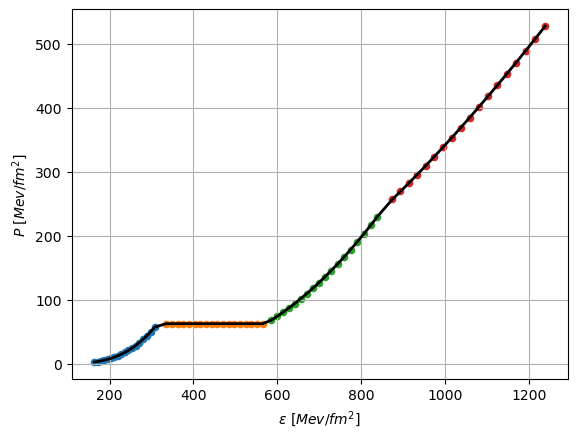

In [5]:
plt.scatter(e1_b[1:-1], P1_b[1:-1],s=20);
plt.scatter(e2_b[1:-1], P2_b[1:-1],s=20);
plt.scatter(e3_b[1:-1], P3_b[1:-1],s=20);
plt.scatter(e4_b[1:-1], P4_b[1:-1],s=20);

plt.plot(e_arr, P_arr, linewidth = 2, color = "black");
plt.grid()
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.show();

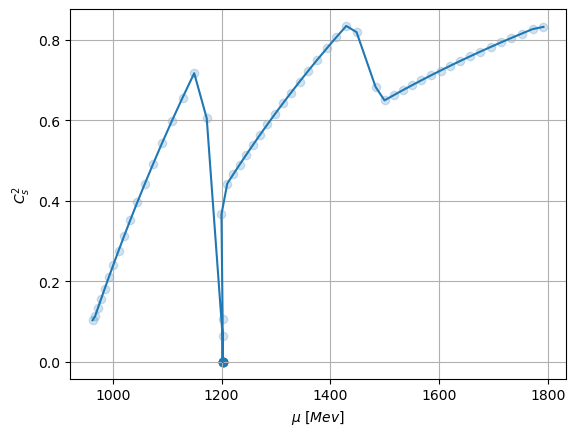

In [6]:
plt.scatter(mu_arr,cs2,alpha=0.2);
plt.plot(mu_arr,cs2)
plt.grid()
plt.xlabel(r"$\mu \ [Mev]$")
plt.ylabel(r"$C_s^2$")
plt.show();

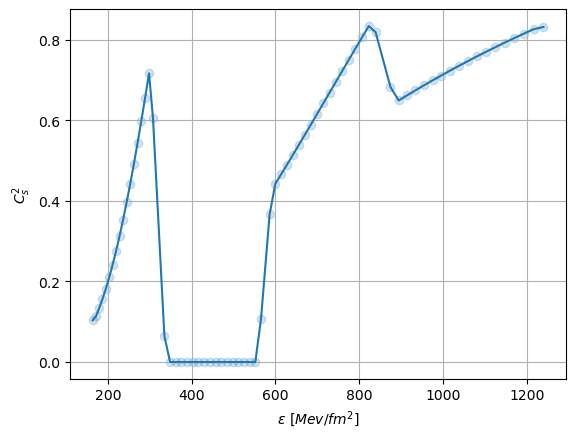

In [7]:
plt.scatter(e_arr,cs2,alpha=0.2);
plt.plot(e_arr,cs2)
plt.grid()
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$C_s^2$")
plt.show();

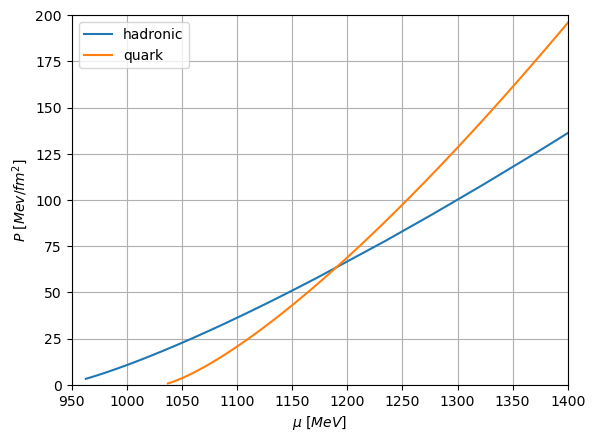

In [8]:
n_arr1 = np.concatenate((n1_b[1:-1], n2_b[1:-1], n3_b[1:-1]))

mu1_b = mu_from_nb(n_arr, K_b[0], Gam_b[0], m0[0])
mu3_b = mu_from_nb(n_arr1, K_b[2], Gam_b[2], m0[2])
mu4_b = mu_from_nb(n4_b[1:-1], K_b[3], Gam_b[3], m0[3])
mu_quark = np.concatenate((mu3_b,mu4_b))

P_1_all = P_from_nb(n_arr, K_b[0], Gam_b[0])
P_3_all = P_from_nb(n_arr, K_b[2], Gam_b[2])

plt.plot(mu1_b, P_1_all, label = "hadronic")
plt.plot(mu_quark, P_3_all, label = "quark")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.xlim([950,1400])
plt.ylim([0,200])
plt.grid()

In [9]:
# Assuming mu1_b, P_1_all, mu_quark, and P_3_all are already defined
x1 = np.array(mu1_b)
y1 = np.array(P_1_all)

x2 = np.array(mu_quark)
y2 = np.array(P_3_all)

P_h_int_func = interpolate.interp1d(x1, y1)
P_q_int_func = interpolate.interp1d(x2, y2)

mu_new = np.linspace(1050, 1385, 1000)
P_had_array = P_h_int_func(mu_new)
P_quark_array = P_q_int_func(mu_new)

# Calculate the difference and find the intersection
y_diff = np.abs(P_had_array - P_quark_array)
i_intersect = mu_new[index_intersect]
y_intersect = P_had_array[index_intersect]

print("The index is:", index_intersect, "the mu value is:", x_intersect)
print("Critical Chemical Potential is, mu_c:", x_intersect)

# Split the arrays at the intersection point
mu_had = mu_new[:index_intersect + 1]
P_had = P_had_array[:index_intersect + 1]
mu_quark = mu_new[index_intersect:]
P_quark = P_quark_array[index_intersect:]

# Plotting the updated arrays
plt.plot(mu_had, P_had, label='Hadronic Phase')
plt.plot(mu_quark, P_quark, label='Quark Phase')
plt.scatter(x_intersect, y_intersect, color="red", alpha=0.7, label='Intersection Point')
plt.ylim([58, 70])
plt.xlim([1180, 1200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [MeV/fm^2]$")
plt.legend()
plt.grid()
plt.show()ndex_intersect = np.argmin(y_diff)

SyntaxError: invalid syntax (2154022965.py, line 39)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


The index is : 417 the mu value is:  1189.8348348348347


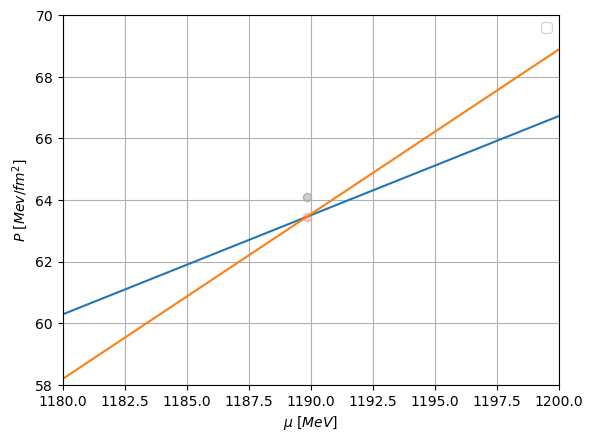

1189.8348348348347 63.452713316194014
Critical Chemical Potential is, mu_c: 1189.8348348348347


In [10]:
x1 = np.array(mu1_b)
y1 = np.array(P_1_all)

x2 = np.array(mu_quark)
y2 = np.array(P_3_all)

P_h_int_func = interpolate.interp1d(x1, y1)
P_q_int_func = interpolate.interp1d(x2, y2)

mu_new = np.linspace(1050, 1385, 1000)
P_had_array = P_h_int_func(mu_new)
P_quark_array = P_q_int_func(mu_new)


y_diff = np.abs(P_h_int_func(mu_new) - P_q_int_func(mu_new))
print("The index is :",np.argmin(y_diff), "the mu value is: ", mu_new[np.argmin(y_diff)])
x_intersect = mu_new[np.argmin(y_diff)]
y_intersect = P_h_int_func(x_intersect)
#%%
plt.plot(mu_new, P_had_array)
plt.plot(mu_new, P_quark_array)
plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2)
plt.scatter(x_intersect, y_intersect*(1 + 0.01), color = "black", alpha = 0.2)
plt.ylim([58,70])
plt.xlim([1180,1200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()
plt.show()
print(x_intersect, y_intersect)
print("Critical Chemical Potential is, mu_c:", x_intersect)


In [11]:
@jit(nopython=True)
def quad_P(mu_c, mu, alpha, beta, delP, P_c):
    t1 = alpha*(mu - mu_c)**2
    t2 = beta*(mu - mu_c)
    t3 = (1+delP)*P_c
    re = t1 + t2 + t3
    return re

@jit(nopython=True)
def alpha(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        re = (t1 - t2)/(mu_c_q - mu_c_h)
    return re

@jit(nopython=True)
def beta(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        t3 = (P_q - P_h)/(mu_c_q - mu_c_h)
        re = t1 + t2 - t3
    return re

1186.4814814814815 1193.1881881881882


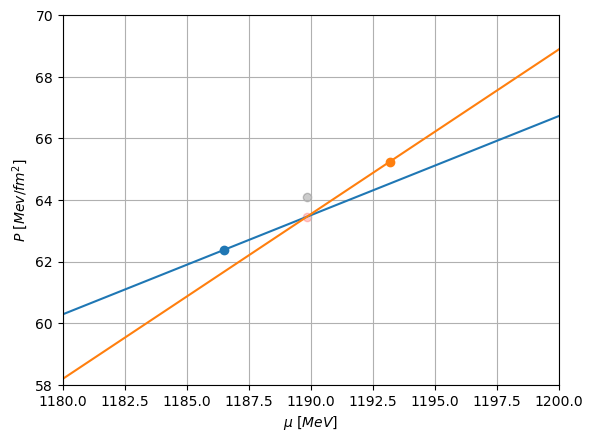

In [12]:
mu_c_h = mu_new[np.argmin(y_diff) - 10]
mu_c_q = mu_new[np.argmin(y_diff) + 10]
P_h = P_h_int_func(mu_c_h)
P_q = P_q_int_func(mu_c_q)

print(mu_c_h, mu_c_q)
plt.scatter(mu_c_h, P_h)
plt.scatter(mu_c_q, P_q)
plt.plot(mu_new, P_had_array)
plt.plot(mu_new, P_quark_array)
plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2)
plt.scatter(x_intersect, y_intersect*(1 + 0.01), color = "black", alpha = 0.2)
plt.ylim([58,70])
plt.xlim([1180,1200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.grid()
plt.show()

In [13]:
delta_P_arr = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.10]
A = []
B = []
mu_c_h_arr  = []
mu_c_q_arr = []
P_c_h_arr = []
P_c_q_arr = []


for z in range(len(delta_P_arr)):
    delta_P = delta_P_arr[z]
    found = False
    for i in range(len(mu_new)):
        if found:
            break
        mu_c_h = mu_new[i]
        for j in range(len(mu_new)):
            mu_c_q = mu_new[j]
            P_h = P_h_int_func(mu_c_h)
            P_q = P_q_int_func(mu_c_q)

            alp = alpha(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)
            bet = beta(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)

            if alp > 0:
                P_m = quad_P(x_intersect, mu_new, alp, bet, delta_P, y_intersect)
                m_h_P_diff = [x - y for x, y in zip(P_m[:np.argmin(y_diff)], P_had_array[:np.argmin(y_diff)])]
                m_q_P_diff = [x - y for x, y in zip(P_m[np.argmin(y_diff):], P_quark_array[np.argmin(y_diff):])]

                if min(m_h_P_diff) >= 0 and min(m_q_P_diff) >= 0:
                    print(min(m_h_P_diff), min(m_q_P_diff))
                    A.append(alp)
                    B.append(bet)
                    mu_c_h_arr.append(mu_c_h)
                    mu_c_q_arr.append(mu_c_q)
                    P_c_h_arr.append(P_h)
                    P_c_q_arr.append(P_q)
                    found = True
                    break

    if found:
        continue


print(len(A), A, B)

0.0 0.0
0.0 0.0
0.0 0.0
0.0 0.0
7.105427357601002e-15 0.0
7.105427357601002e-15 0.0
0.0 0.0
7.105427357601002e-15 0.0
8 [0.004602063359679466, 0.002556826539352172, 0.0018493323377004698, 0.0012626233712316126, 0.0011116348146140698, 0.000921133383878102, 0.0008568507091246093, 0.0008048109238753944] [0.4299256358957985, 0.43214042554904086, 0.433804661500098, 0.43715532610154006, 0.4388032884079217, 0.441756453056327, 0.4430876422162929, 0.4443503304751757]


(50.0, 92.0)

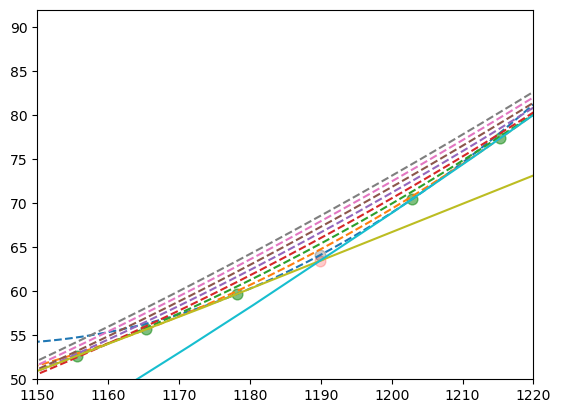

In [14]:
P_m1 = quad_P(x_intersect, mu_new, A[0], B[0], delta_P_arr[0], y_intersect)
P_m2 = quad_P(x_intersect, mu_new, A[1], B[1], delta_P_arr[1], y_intersect)
P_m3 = quad_P(x_intersect, mu_new, A[2], B[2], delta_P_arr[2], y_intersect)
P_m4 = quad_P(x_intersect, mu_new, A[3], B[3], delta_P_arr[3], y_intersect)
P_m5 = quad_P(x_intersect, mu_new, A[4], B[4], delta_P_arr[4], y_intersect)
P_m6 = quad_P(x_intersect, mu_new, A[5], B[5], delta_P_arr[5], y_intersect)
P_m7 = quad_P(x_intersect, mu_new, A[6], B[6], delta_P_arr[6], y_intersect)
P_m8 = quad_P(x_intersect, mu_new, A[7], B[7], delta_P_arr[7], y_intersect)


plt.plot(mu_new, P_m1, linestyle="--")
plt.plot(mu_new, P_m2, linestyle="--")
plt.plot(mu_new, P_m3, linestyle="--")
plt.plot(mu_new, P_m4, linestyle="--")
plt.plot(mu_new, P_m5, linestyle="--")
plt.plot(mu_new, P_m6, linestyle="--")
plt.plot(mu_new, P_m7, linestyle="--")
plt.plot(mu_new, P_m8, linestyle="--")


plt.scatter(mu_c_h_arr, P_c_h_arr, color = "green", alpha = 0.5, s = 60)
plt.scatter(mu_c_q_arr, P_c_q_arr, color = "green", alpha = 0.5, s = 60)
#plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2)

plt.plot(mu_new, P_had_array)
plt.plot(mu_new, P_quark_array)
plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2, s = 60)
plt.scatter(x_intersect, y_intersect*(1 + delta_P_arr[0]), color = "black", alpha = 0.2, s = 60)

plt.xlim([1150,1220])
plt.ylim([50,92])

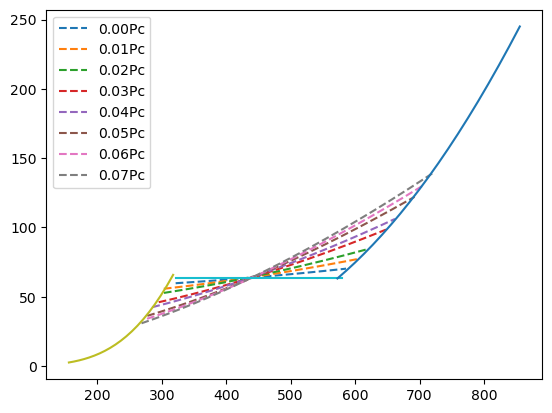

In [15]:
mu_new_arr = list(mu_new)
P_had_array_arr = list(P_had_array)
P_quark_array_arr = list(P_quark_array)
for i in range(len(mu_c_h_arr)):
    P_m1 = quad_P(x_intersect, mu_new, A[i], B[i], delta_P_arr[i], y_intersect)

    ind_h0 = mu_new_arr.index(mu_c_h_arr[i])
    ind_q0 = mu_new_arr.index(mu_c_q_arr[i])

    P_10_reqd = P_m1[ind_h0:ind_q0]
    mu_10_req = mu_new[ind_h0:ind_q0]
    n_10_re1 = np.gradient(P_10_reqd, mu_10_req)
    e_10_req = (n_10_re1*mu_10_req)-P_10_reqd

    plt.plot(e_10_req, P_10_reqd, linestyle = "--", label = f"0.0{i}Pc")

plt.plot(e1_b, P1_b)
plt.plot(e2_b, P2_b)
plt.plot(e3_b, P3_b)
#plt.plot(e4_b, P4_b)
plt.legend(loc="upper left")

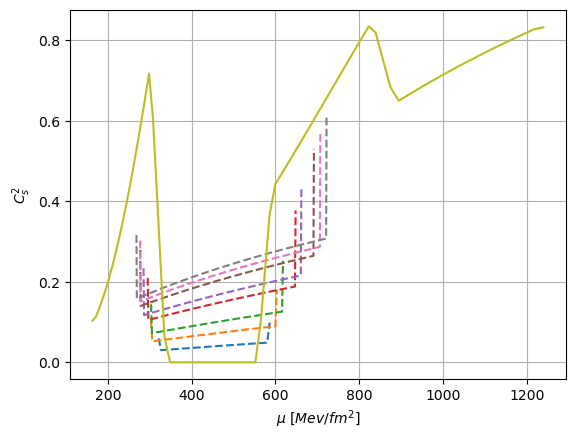

In [16]:
mu_new_arr = list(mu_new)
P_had_array_arr = list(P_had_array)
P_quark_array_arr = list(P_quark_array)
for i in range(len(mu_c_h_arr)):
    P_m1 = quad_P(x_intersect, mu_new, A[i], B[i], delta_P_arr[i], y_intersect)

    ind_h0 = mu_new_arr.index(mu_c_h_arr[i])
    ind_q0 = mu_new_arr.index(mu_c_q_arr[i])

    P_10_reqd = P_m1[ind_h0:ind_q0]
    mu_10_req = mu_new[ind_h0:ind_q0]
    n_10_re1 = np.gradient(P_10_reqd, mu_10_req)
    e_10_req = (n_10_re1*mu_10_req)-P_10_reqd
    cs2_10_req = np.gradient(P_10_reqd,e_10_req)

    plt.plot(e_10_req, cs2_10_req, linestyle = "--", label = f"0.0{i}Pc")


#plt.scatter(mu_arr,cs2,alpha=0.2);
plt.plot(e_arr,cs2)
plt.grid()
plt.xlabel(r"$\mu \ [Mev/fm^2]$")
plt.ylabel(r"$C_s^2$")
plt.show();

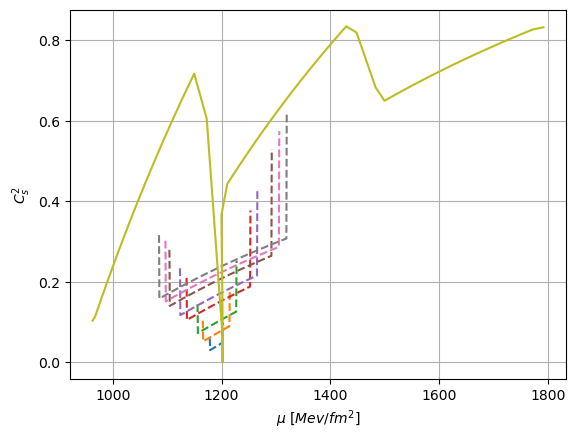

In [17]:
mu_new_arr = list(mu_new)
P_had_array_arr = list(P_had_array)
P_quark_array_arr = list(P_quark_array)
for i in range(len(mu_c_h_arr)):
    P_m1 = quad_P(x_intersect, mu_new, A[i], B[i], delta_P_arr[i], y_intersect)

    ind_h0 = mu_new_arr.index(mu_c_h_arr[i])
    ind_q0 = mu_new_arr.index(mu_c_q_arr[i])

    P_10_reqd = P_m1[ind_h0:ind_q0]
    mu_10_req = mu_new[ind_h0:ind_q0]
    n_10_re1 = np.gradient(P_10_reqd, mu_10_req)
    e_10_req = (n_10_re1*mu_10_req)-P_10_reqd
    cs2_10_req = np.gradient(P_10_reqd,e_10_req)

    plt.plot(mu_10_req, cs2_10_req, linestyle = "--", label = f"0.0{i}Pc")


#plt.scatter(mu_arr,cs2,alpha=0.2);
plt.plot(mu_arr,cs2)
plt.grid()
plt.xlabel(r"$\mu \ [Mev/fm^2]$")
plt.ylabel(r"$C_s^2$")
plt.show();

In [18]:
import numpy as np
from numba import jit
import time
from scipy.interpolate import interp1d

G=1
c=1
M01 = 1.474 * 10**3

G1 = 6.67*10**(-11)             ############ N m^2/ kg^2
c1 = 3*10**(8)                  ############ m / s

Mev_fm3_to_GU = 1.6* 10**32 * G1/c1**4


from numba import jit
#@jit(nopython = True)
def love_number(C,y):
  k2 = 8 / 5 * C ** 5 * (1 - 2 * C) **(2) * (2 + 2 * C * (y - 1) - y) * (2 * C * (6 - 3 * y + 3 * C * (5 * y - 8)) + 4 * C ** 3 * (13 - 11 * y + C * (3 * y - 2) + 2 * C ** 2 * (1 + y)) + 3 * (1 - 2 * C) ** 2 * (2 - y + 2 * C * (y - 1)) * (np.log(1 - 2 * C))) ** (-1)
  return k2


#@jit(nopython = True)
def beta_and_H(r, p, H, m, beta, parr, earr):
    dp = p * 0.005

    el_3 = en_dens(parr, earr, p - 3 * dp)
    el_2 = en_dens(parr, earr, p - 2 * dp)
    el_1 = en_dens(parr, earr, p - 1 * dp)
    er_3 = en_dens(parr, earr, p + 3 * dp)
    er_2 = en_dens(parr, earr, p + 2 * dp)
    er_1 = en_dens(parr, earr, p + 1 * dp)

    de_dp = (-1 / 60 * el_3 + 3 / 20 * el_2 - 3 / 4 * el_1 + 3 / 4 * er_1 - 3 / 20 * er_2 + 1 / 60 * er_3) / dp

    #G = 6.67430e-11  # Gravitational constant
    #c = 299792458.0  # Speed of light
    G = 1
    c = 1

    e = en_dens(parr, earr, p)
    dbeta_dr = 2 * (1 - 2 * m / r ) ** (-1) *H * (-2 * np.pi * G / c ** 2 * (5 * e + 9 * p / c ** 2 + de_dp * c ** 2 * (e + p / c ** 2)) + 3 / r ** 2 + 2 * (1 - 2 * m / r ) ** (-1) * ( m / r ** 2 + G / c ** 4 * 4 * np.pi * r * p) ** 2) + 2 * (1 - 2 * m / r ) ** (-1) *beta / r * (-1 + m / r + 2 * np.pi * r ** 2 * G / c ** 2 * (e - p / c ** 2))

    dHdr = beta
    return dbeta_dr, dHdr

@jit(nopython = True)
def en_dens(parr, earr, p):
  if p < min(parr) or p > max(parr):
    e = 0
  else:
    e = ene_interp(parr, earr, p)
  return e

@jit(nopython = True)
def find_ind(arr, val):
    for i, item in enumerate(arr):
        if val > item:
            continue
        else:
            return i
    return len(arr)

class PressureOutOfRangeError(Exception):
    pass

@jit(nopython = True)
def en_dens(parr, earr, p):
  if p < min(parr) or p > max(parr):
    e = 0
  else:
    e = ene_interp(parr, earr, p)
  return e


@jit(nopython = True)
def ene_interp(pre_arr, ene_arr, pressure):
    if pressure < min(pre_arr) or pressure > max(pre_arr):
        raise PressureOutOfRangeError("Pressure is out of range.")
    else:
        ind = find_ind(pre_arr, pressure)
        left_p = pre_arr[ind - 1]
        right_p = pre_arr[ind]
        left_e = ene_arr[ind-1]
        right_e = ene_arr[ind]
        ene_val = (pressure - left_p)*(right_e - left_e)/(right_p - left_p) + left_e
    return ene_val

@jit(nopython = True)
def pre_interp(pre_arr, ene_arr, energy):
    if energy < min(ene_arr) or energy > max(ene_arr):
        raise PressureOutOfRangeError("Energy is out of range.")
    else:
        ind = find_ind(ene_arr, energy)
        left_p = pre_arr[ind - 1]
        right_p = pre_arr[ind]
        left_e = ene_arr[ind-1]
        right_e = ene_arr[ind]
        pre_val = (energy - left_e)*(right_p - left_p)/(right_e - left_e) + left_p
    return pre_val

def cs2_interp(cs2_arr, pre_arr, pressure):
    if pressure < min(pre_arr) or pressure > max(pre_arr):
        raise PressureOutOfRangeError("Pressure is out of range.")
    else:
        ind = find_ind(pre_arr, pressure)
        left_c = cs2_arr[ind - 1]
        right_c = cs2_arr[ind]
        left_p = pre_arr[ind-1]
        right_p = pre_arr[ind]
        cs2_val = (pressure - left_p)*(right_c - left_c)/(right_p - left_p) + left_c
    return cs2_val

@jit(nopython = True)
def Tov_eqn(P, r, m, dens, press, G, c, min_pressure):
    if P < min_pressure:
        return 0.0
    else:
        eden = ene_interp(press, dens, P)
        return -(G * ((P / c ** 2) + eden) * (m + 4 * np.pi * r ** 3 * P / c ** 2)) / (r * (r - 2 * G * m / c ** 2))

@jit(nopython = True)
def mass_eqn(r, ene):
    return 4 * np.pi * r ** 2 * ene


def TOV_module(cen_dens, pressure, density, exit_Pre,love=False, to_print=False):
    asi = 0
    P_exit =exit_Pre
    for i in range(len(cen_dens)):
        press = np.array(pressure)
        dens = np.array(density)
        d = cen_dens[i]
        P0 = pre_interp(press, dens, d)
        r = 10
        P = P0
        m = mass_eqn(r,d)
        h = 1
        a0 = 1
        H0 = a0*r**2
        beta0 = 2*a0*r
        min_pressure = min(press)
        beta = beta0
        H = H0
        if  love == True:
            #print("Entering Love loop")
            while P > P_exit :
                k1_m = mass_eqn(r, ene_interp(press, dens, P))
                k2_m = mass_eqn(r + h / 2, ene_interp(press, dens, P))
                k3_m = mass_eqn(r + h / 2, ene_interp(press, dens, P))
                k4_m = mass_eqn(r + h, ene_interp(press, dens, P))

                k1_p = Tov_eqn(P, r, m, dens, press, G, c, min_pressure)
                k2_p = Tov_eqn(P + k1_p * h / 2, r + h / 2, m + k1_m * h / 2, dens, press, G, c, min_pressure)
                k3_p = Tov_eqn(P + k2_p * h / 2, r + h / 2, m + k2_m * h / 2, dens, press, G, c, min_pressure)
                k4_p = Tov_eqn(P + k3_p * h, r + h, m + k3_m * h, dens, press, G, c, min_pressure)

                k1_dbeta_dr, k1_dHdr = beta_and_H(r, P, H, m, beta, press, dens)
                k2_dbeta_dr, k2_dHdr = beta_and_H(r + 0.5 * h, P + 0.5 * h * k1_p, H + 0.5 * h * k1_dHdr, m + 0.5*h*k1_m, beta + 0.5*h*k1_dbeta_dr, press, dens)
                k3_dbeta_dr, k3_dHdr = beta_and_H(r + 0.5 * h, P + 0.5 * h * k2_p, H + 0.5 * h * k2_dHdr, m + 0.5*h*k2_m, beta + 0.5*h*k2_dbeta_dr, press, dens)
                k4_dbeta_dr, k4_dHdr = beta_and_H(r + h, P + h * k3_p, H + h * k3_dHdr, m + h*k3_m, beta + h*k3_dbeta_dr, press, dens)

                beta = beta + (h / 6.0) * (k1_dbeta_dr + 2 * k2_dbeta_dr + 2 * k3_dbeta_dr + k4_dbeta_dr)
                H = H + (h / 6.0) * (k1_dHdr + 2 * k2_dHdr + 2 * k3_dHdr + k4_dHdr)
                P += h * (k1_p + 2 * k2_p + 2 * k3_p + k4_p) / 6
                m += h * (k1_m + 2 * k2_m + 2 * k3_m + k4_m) / 6
                r += h
            R.append(r/1000)
            M.append(m/M01)
            y = r * beta/ (H)
            C = m/r
            k2 = love_number(C,y)
            Com.append(C)
            Love.append(k2)
            if to_print == True:
                print("star ", i," done")
        else:
            #print("Entering No Love loop")
            while P > P_exit :
                k1_m = mass_eqn(r, ene_interp(press, dens, P))
                k2_m = mass_eqn(r + h / 2, ene_interp(press, dens, P))
                k3_m = mass_eqn(r + h / 2, ene_interp(press, dens, P))
                k4_m = mass_eqn(r + h, ene_interp(press, dens, P))

                k1_p = Tov_eqn(P, r, m, dens, press, G, c, min_pressure)
                k2_p = Tov_eqn(P + k1_p * h / 2, r + h / 2, m + k1_m * h / 2, dens, press, G, c, min_pressure)
                k3_p = Tov_eqn(P + k2_p * h / 2, r + h / 2, m + k2_m * h / 2, dens, press, G, c, min_pressure)
                k4_p = Tov_eqn(P + k3_p * h, r + h, m + k3_m * h, dens, press, G, c, min_pressure)

                P += h * (k1_p + 2 * k2_p + 2 * k3_p + k4_p) / 6
                m += h * (k1_m + 2 * k2_m + 2 * k3_m + k4_m) / 6
                r += h
            R.append(r/1000)
            M.append(m/M01)
            if to_print == True:
                print("star ", i," done")
    return R,M,Com,Love

In [19]:
G1 = 6.67*10**(-11)             ############ N m^2/ kg^2
c1 = 3*10**(8)                  ############ m / s

Mev_fm3_to_GU = 1.6* 10**32 * G1/c1**4

In [22]:
p_arr=Mev_fm3_to_GU*P_arr
E_arr=Mev_fm3_to_GU*e_arr

R =[]
M =[]
Com = []
Love = []

cden_arr = np.logspace(np.log10((min(E_arr)*1.1)),np.log10((max(E_arr)*0.99)),80)
radius,mass,comp,love_number=TOV_module(cden_arr,p_arr,E_arr,min(p_arr)*1.1,to_print=True,love=True)


star  0  done
star  1  done
star  2  done
star  3  done
star  4  done
star  5  done
star  6  done
star  7  done
star  8  done
star  9  done
star  10  done
star  11  done
star  12  done
star  13  done
star  14  done
star  15  done
star  16  done
star  17  done
star  18  done
star  19  done
star  20  done
star  21  done
star  22  done
star  23  done
star  24  done
star  25  done
star  26  done
star  27  done
star  28  done
star  29  done
star  30  done
star  31  done
star  32  done
star  33  done
star  34  done
star  35  done
star  36  done
star  37  done
star  38  done
star  39  done
star  40  done
star  41  done
star  42  done
star  43  done
star  44  done
star  45  done
star  46  done
star  47  done
star  48  done
star  49  done
star  50  done
star  51  done
star  52  done
star  53  done
star  54  done
star  55  done
star  56  done
star  57  done
star  58  done
star  59  done
star  60  done
star  61  done
star  62  done
star  63  done
star  64  done
star  65  done
star  66  done
star 

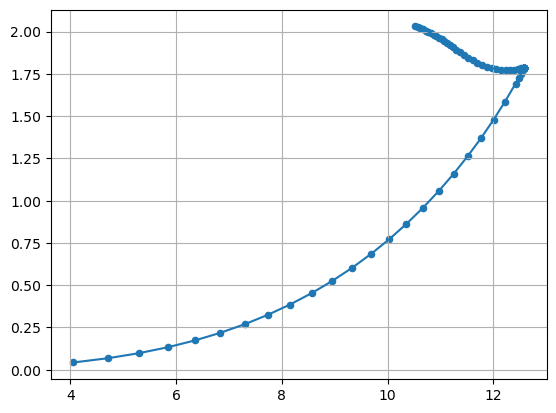

In [23]:
plt.scatter(radius,mass,s=20)
plt.plot(radius,mass)
plt.grid()

Part 2

In [24]:
P_arr

array([  3.2017519 ,   4.0158256 ,   4.98690699,   6.13652042,
         7.48804568,   9.06679149,  10.90006865,  13.01726309,
        15.44990859,  18.23175937,  21.39886243,  24.98962972,
        29.04491008,  33.60806106,  38.72502055,  44.44437814,
        50.8174465 ,  57.89833243,  63.177     ,  63.177     ,
        63.177     ,  63.177     ,  63.177     ,  63.177     ,
        63.177     ,  63.177     ,  63.177     ,  63.177     ,
        63.177     ,  63.177     ,  63.177     ,  63.177     ,
        63.177     ,  63.177     ,  63.177     ,  63.177     ,
        68.69386063,  74.58775672,  80.8530264 ,  87.5049516 ,
        94.55912235, 102.03143684, 109.93810141, 118.29563051,
       127.12084674, 136.43088082, 146.24317164, 156.57546619,
       167.44581961, 178.8725952 , 190.87446436, 203.47040665,
       216.67970975, 230.5219695 , 257.24426304, 269.85654063,
       282.85953115, 296.25852356, 310.05878917, 324.26558206,
       338.88413939, 353.91968171, 369.37741327, 385.26

In [25]:
mu_arr

array([ 962.76608623,  967.35686014,  972.59230587,  978.52927856,
        985.22693366,  992.74671922, 1001.15236865, 1010.50989363,
       1020.88757744, 1032.35596847, 1044.98787398, 1058.85835414,
       1074.04471621, 1090.62650895, 1108.68551725, 1128.30575683,
       1149.57346925, 1172.57711692, 1201.75      , 1201.75      ,
       1201.75      , 1201.75      , 1201.75      , 1201.75      ,
       1201.75      , 1201.75      , 1201.75      , 1201.75      ,
       1201.75      , 1201.75      , 1201.75      , 1201.75      ,
       1201.75      , 1201.75      , 1201.75      , 1201.75      ,
       1199.64322873, 1210.33103276, 1221.46322311, 1233.04885141,
       1245.09696928, 1257.61662835, 1270.61688026, 1284.10677664,
       1298.09536911, 1312.5917093 , 1327.60484885, 1343.14383937,
       1359.21773252, 1375.8355799 , 1393.00643316, 1410.73934392,
       1429.04336381, 1447.92754446, 1482.89462812, 1499.27949007,
       1515.88803916, 1532.7195247 , 1549.77321088, 1567.04837

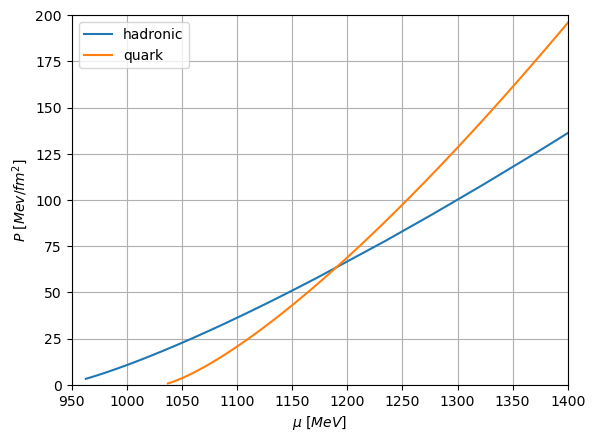

In [27]:
plt.plot(mu1_b, P_1_all, label = "hadronic")
plt.plot(mu_quark, P_3_all, label = "quark")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.xlim([950,1400])
plt.ylim([0,200])
plt.grid()

In [46]:


print(x_intersect)
print(y_intersect)

1189.8348348348347
63.452713316194014


In [43]:
P_min = min(P_1_all)
mu_min = min(mu1_b)

print(r"The minimum value of P                      : "+str(P_min)+" [Mev/fm^2] ")
print(r"The corresponding value of mu for minimum P : "+str(mu_min)+" [Mev] ")

The minimum value of P                      : 3.201751899985748 [Mev/fm^2] 
The corresponding value of mu for minimum P : 962.7660862286051 [Mev] 


In [ ]:
mu_crit = 
p_crit

In [29]:
# Define the two points (x1, y1) and (x2, y2) the quadratic must pass through
x1, y1 = mu_min, P_min
x2, y2 = ,

# Array of points (xi, yi) representing the other curve
x_points = mu_quark
y_points = P_3_all

# Define the quadratic function
def quadratic(x, a, b, c):
    return a * x**2 + b * x + c

# Define the objective function for optimization
def objective(params):
    a, b, c = params
    # Equation constraints
    eq1 = quadratic(x1, a, b, c) - y1
    eq2 = quadratic(x2, a, b, c) - y2
    # Compute differences between quadratic and other curve points
    differences = quadratic(x_points, a, b, c) - y_points
    # Combine the constraints and the differences
    return eq1**2 + eq2**2 + np.sum(differences**2)

# Initial guess for parameters a, b, c
initial_guess = [1, 1, 1]

# Optimize
result = minimize(objective, initial_guess)

# Extract optimized parameters
a_opt, b_opt, c_opt = result.x

print(f"Optimized coefficients: a = {a_opt}, b = {b_opt}, c = {c_opt}")


3.201751899985748